This notebook runs a linear decoding procedure over time for different feedback selectivity - G values
based on the BOLD signal and on the firing rate. In all experiments, population A was stimulated and we
are trying to see if we can detect that this was the case. We take a number of trials for each selectivity-G pair
and run the decoding for various time points across trials to see whether/how the accuracy decreases over time.
We take half a second steps, average between -50ms and +50ms
for each center point and perform decoding across trials.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
from scipy.ndimage import gaussian_filter1d


plot_params = {
    "figure.dpi": "600",
    "axes.labelsize": 20,
    "axes.linewidth": 1.5,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.title_fontsize": 16,
    "legend.fontsize": 15,
    "xtick.major.size": 3.5,
    "xtick.major.width": 1.5,
    "xtick.minor.size": 2.5,
    "xtick.minor.width": 1.5,
    "ytick.major.size": 3.5,
    "ytick.major.width": 1.5,
    "ytick.minor.size": 2.5,
    "ytick.minor.width": 1.5,
}
plt.rcParams.update(plot_params)

In [ ]:
bold_decoding_acc = []
fr_decoding_acc = []
selectivities = [1, 0.95, 0.9, 0.85, 0.8, 0.75, 0.7, 0.65, 0.6, 0.55, 0.5]
all_acc_bold = {} # selectivity: acc_success_bold
all_t_bold = {} # selectivity: center_time_steps*dt
all_acc_fr = {} # selectivity: acc_success_bold
all_t_fr = {} # selectivity: center_time_steps*dt
for select in selectivities:
    print(f'Selectivity: {select}')
    bold_data_successful = np.load(f'saved_plots/Figure_6D/bold_signal_{select}.npy', allow_pickle=True) # Data for successful trial
    fr_data_successful = np.load(f'saved_plots/Figure_6D/activity_trace_fr_{select}.npy', allow_pickle=True) # Data for successful trial
    dt = 0.5e-3 # Time resolution of simulation
    # Data when stimulus was given to population A
    time_to_cut = 10 # s
    index_area_to_decode = 8
    samples_to_cut = int(time_to_cut/dt)
    bold_A_data_successful = np.array(bold_data_successful[:, 0])
    bold_A_data_successful = np.array([trial[samples_to_cut:, index_area_to_decode] for trial in bold_A_data_successful])
    bold_B_data_successful = np.array(bold_data_successful[:, 1])
    bold_B_data_successful = np.array([trial[samples_to_cut:, index_area_to_decode] for trial in bold_B_data_successful])

    standard_deviation_bold_A_successful = np.std(bold_A_data_successful, axis=0, ddof=1)
    mean_bold_A_successful = np.mean(bold_A_data_successful, axis=0)
    standard_deviation_bold_B_successful = np.std(bold_B_data_successful, axis=0, ddof=1)
    mean_bold_B_successful = np.mean(bold_B_data_successful, axis=0)

    fr_A_data_successful = np.array(fr_data_successful[:, 0])
    fr_A_data_successful = np.array([trial[samples_to_cut:, index_area_to_decode] for trial in fr_A_data_successful])
    fr_B_data_successful = np.array(fr_data_successful[:, 1])
    fr_B_data_successful = np.array([trial[samples_to_cut:, index_area_to_decode] for trial in fr_B_data_successful])
    standard_deviation_fr_A_successful = np.std(fr_A_data_successful, axis=0, ddof=1)
    mean_fr_A_successful = np.mean(fr_A_data_successful, axis=0)
    standard_deviation_fr_successful = np.std(fr_B_data_successful, axis=0, ddof=1)
    mean_fr_B_successful = np.mean(fr_B_data_successful, axis=0)
    
    from sklearn.model_selection import train_test_split
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import SGDClassifier
    from sklearn.model_selection import cross_val_score

    time_in_s = 10 # we start from the start of the simulation that doesn't include the transient
    start_decoding_step = int((time_in_s - time_to_cut) / dt)
    half_second_steps = int(0.5 / dt)
    fifty_ms_step = int(0.05/dt)
    # Instead of taking just one time point, I want to take 50ms to the left and right and average
    total_time_steps = bold_A_data_successful[0].shape[0]
    center_time_steps = np.arange(start_decoding_step, total_time_steps, half_second_steps)
    center_time_steps[-1] = center_time_steps[-1] - fifty_ms_step # Make sure the last time step is not at the end of the array
    half_window = fifty_ms_step # number of samples left/right of center
    # I now have the centers, I need to average between -50ms and +50ms for each center point
    bold_A_successful_coord = np.array([
        [ts[max(0, c - half_window):min(len(ts), c + half_window + 1)].mean()
        for c in center_time_steps]
        for ts in bold_A_data_successful
    ])

    bold_B_successful_coord = np.array([
        [ts[max(0, c - half_window):min(len(ts), c + half_window + 1)].mean()
        for c in center_time_steps]
        for ts in bold_B_data_successful
    ])
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import SGDClassifier
    from sklearn.model_selection import cross_val_score

    pipe_BOLD = make_pipeline(StandardScaler(), SGDClassifier(random_state=42))

    def time_resolved_decoding(A, B):
        n_trials, n_times = A.shape
        print(f'There are {n_trials} trials and {n_times} time points in each trial.')
        acc = np.zeros(n_times) # Hold the accuracy of decoding for each time point
        for t in range(n_times): # Iterate over time points
            X_t = np.concatenate([A[:, t], B[:, t]])[:, np.newaxis] # A[:, t] are the time point t across all trials, so concatenation results in (100, 1) for each timepoint
            # The first 50 rows of X_t will be trials of bold signal for A, the next 50 rows for B
            y_t = np.concatenate([np.zeros(n_trials), np.ones(n_trials)]) # First 50 trials are for population A, so they get label 0 and the next for population B which get label 1
            scores = cross_val_score(pipe_BOLD, X_t, y_t, cv=5)
            acc[t] = scores.mean()
        return acc
    acc_success_bold = time_resolved_decoding(bold_A_successful_coord, bold_B_successful_coord)
    all_acc_bold[select] = acc_success_bold
    all_t_bold[select] = center_time_steps * dt
    print("Average decoding BOLD:", acc_success_bold.mean())
    bold_decoding_acc.append(acc_success_bold.mean())
    # find the index of the dip
    t_star = np.argmin(acc_success_bold)
    t_center = center_time_steps[t_star]
    print("Dip at index:", t_star, "center sample:", t_center, 'in seconds:', t_center*dt + time_to_cut)
    for trial in range(bold_A_successful_coord.shape[0]):
        if bold_B_successful_coord[trial, t_star] > bold_A_successful_coord[trial, t_star]:
            print('Could be misclassified')
            
    from sklearn.model_selection import train_test_split
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import SGDClassifier
    from sklearn.model_selection import cross_val_score

    time_in_s = 10 # Start decoding right after transient removal
    start_decoding_step = int((time_in_s - time_to_cut) / dt)
    half_second_steps = int(0.5 / dt)
    fifty_ms_step = int(0.05/dt)
    # Instead of taking just one time point, I want to take 50ms to the left and right and average
    total_time_steps = fr_A_data_successful[0].shape[0]
    center_time_steps = np.arange(start_decoding_step, total_time_steps, half_second_steps)
    center_time_steps[-1] = center_time_steps[-1] - fifty_ms_step # Make sure the last time step is not at the end of the array
    half_window = fifty_ms_step # number of samples left/right of center
    # I now have the centers, I need to average between -50ms and +50ms for each center point
    fr_A_successful_coord = np.array([
        [ts[max(0, c - half_window):min(len(ts), c + half_window + 1)].mean()
        for c in center_time_steps]
        for ts in fr_A_data_successful
    ])

    fr_B_successful_coord = np.array([
        [ts[max(0, c - half_window):min(len(ts), c + half_window + 1)].mean()
        for c in center_time_steps]
        for ts in fr_B_data_successful
    ])
    
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import SGDClassifier
    from sklearn.model_selection import cross_val_score

    pipe_fr = make_pipeline(StandardScaler(), SGDClassifier(random_state=42))

    def time_resolved_decoding(A, B):
        n_trials, n_times = A.shape
        print(f'There are {n_trials} trials and {n_times} time points in each trial.')
        acc = np.zeros(n_times) # Hold the accuracy of decoding for each time point
        for t in range(n_times): # Iterate over time points
            X_t = np.concatenate([A[:, t], B[:, t]])[:, np.newaxis] # A[:, t] are the time point t across all trials, so concatenation results in (100, 1) for each timepoint
            # The first 50 rows of X_t will be trials of bold signal for A, the next 50 rows for B
            y_t = np.concatenate([np.zeros(n_trials), np.ones(n_trials)]) # First 50 trials are for population A, so they get label 0 and the next for population B which get label 1
            scores = cross_val_score(pipe_fr, X_t, y_t, cv=5)
            acc[t] = scores.mean()
        return acc
    acc_success_fr = time_resolved_decoding(fr_A_successful_coord, fr_B_successful_coord)
    all_acc_fr[select] = acc_success_fr
    all_t_fr[select] = center_time_steps * dt
    print("Average decoding FR:", acc_success_fr.mean())
    fr_decoding_acc.append(acc_success_fr.mean())
    # find the index of the dip
    t_star = np.argmin(acc_success_fr)
    t_center = center_time_steps[t_star]
    print("Dip at index:", t_star, "center sample:", t_center, 'in seconds:', t_center*dt + time_to_cut)
    for trial in range(fr_A_successful_coord.shape[0]):
        if fr_B_successful_coord[trial, t_star] > fr_A_successful_coord[trial, t_star]:
            print('Could be misclassified')

Selectivity: 1
There are 10 trials and 81 time points in each trial.
Average decoding BOLD: 0.8537037037037037
Dip at index: 2 center sample: 2000 in seconds: 11.0
Could be misclassified
Could be misclassified
Could be misclassified
Could be misclassified
Could be misclassified
Could be misclassified
Could be misclassified
Could be misclassified
There are 10 trials and 81 time points in each trial.
Average decoding FR: 0.8709876543209878
Dip at index: 0 center sample: 0 in seconds: 10.0
Could be misclassified
Could be misclassified
Could be misclassified
Could be misclassified
Could be misclassified
Selectivity: 0.95
There are 10 trials and 81 time points in each trial.
Average decoding BOLD: 0.8549382716049383
Dip at index: 19 center sample: 19000 in seconds: 19.5
Could be misclassified
Could be misclassified
Could be misclassified
Could be misclassified
There are 10 trials and 81 time points in each trial.
Average decoding FR: 0.8808641975308641
Dip at index: 7 center sample: 7000 in

In [62]:
bold_data_successful = np.load(f'saved_plots/Figure_6D/bold_signal_{select}.npy', allow_pickle=True) # Data for successful trial
fr_data_successful = np.load(f'saved_plots/Figure_6D/activity_trace_fr_{select}.npy', allow_pickle=True) # Data for successful trial

In [63]:
bold_data_successful[:, 0][0].shape

(100001, 100)

[0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1]


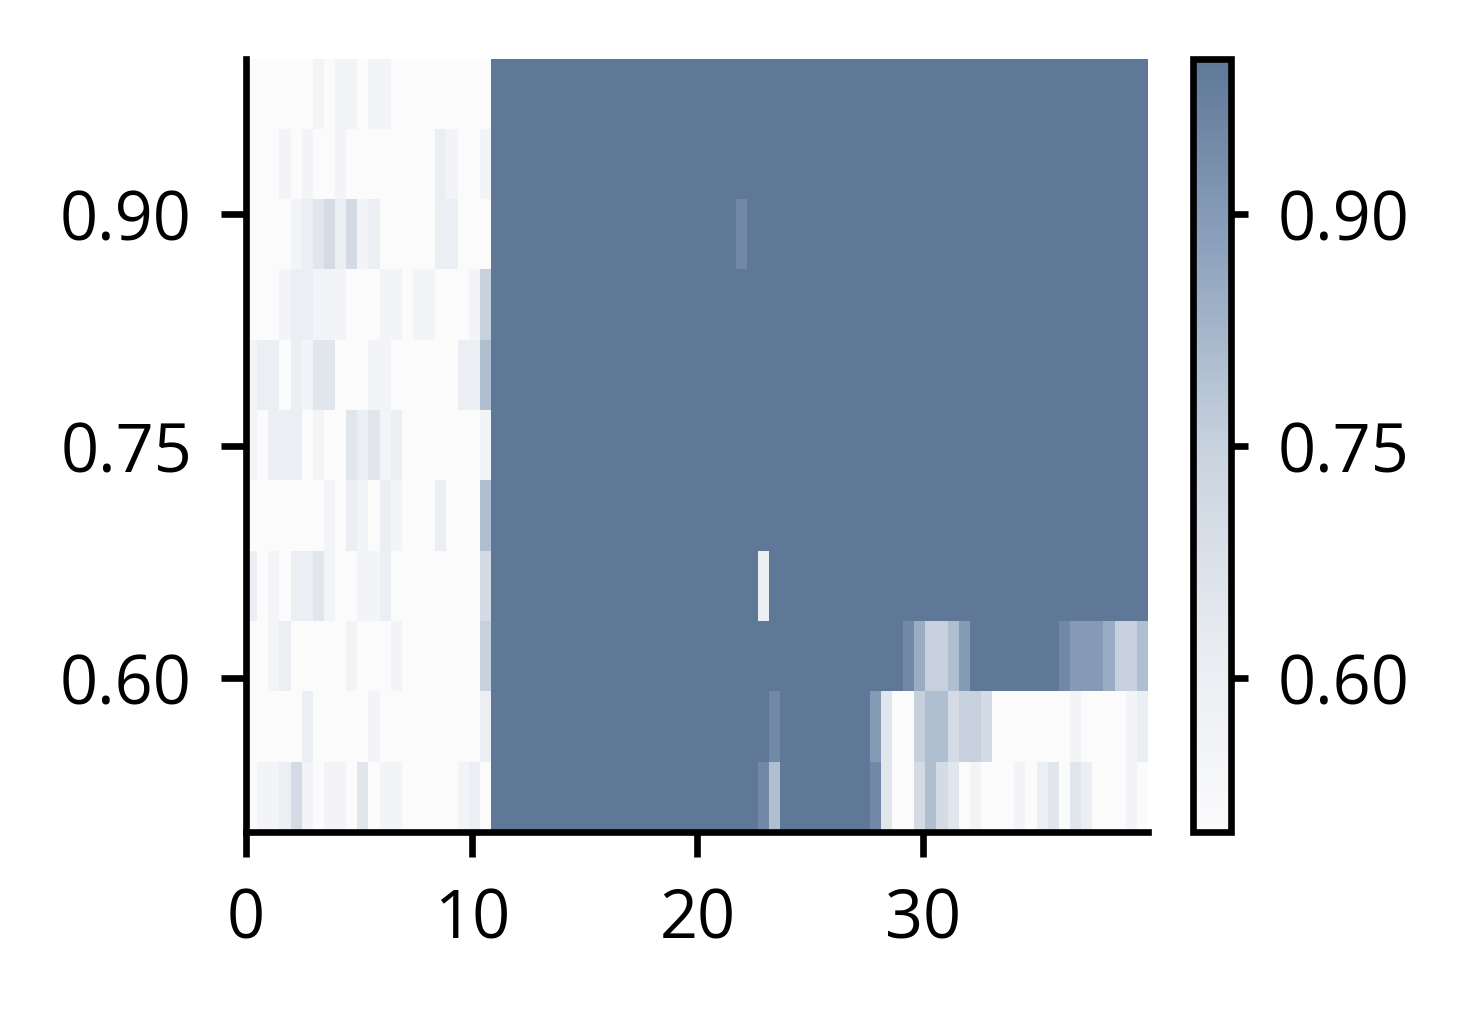

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator

acc_cmap = LinearSegmentedColormap.from_list(
    "acc_slate",
    ["#fbfbfc", "#e7ebf0", "#c8d2de", "#8ea3bd", "#5f7898"],
    N=256
)

fig_params = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.title_fontsize": 8,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}
# BOLD Decoding accurarcy over time (mean across trials)
selectivities = sorted(selectivities)
print(selectivities)
t = all_t_bold[selectivities[0]]
acc_matrix = np.vstack([all_acc_bold[s] for s in selectivities]) # shape (n_sel, n_time)

# figsize is in inches, so divide the cm by 2.54
CM = 2.54
W = (18.4 / 3 - 0.2) / CM   # 5.93cm
H = 4 / CM

with mpl.rc_context(fig_params):
    # constrained_layout fits the colorbar without changing the figure size
    fig, ax = plt.subplots(figsize=(W, H), constrained_layout=True)
    im = ax.imshow(
        acc_matrix, aspect='auto', origin='lower',
        extent=[t[0], t[-1], selectivities[0], selectivities[-1]],
        vmin=0.5, vmax=1.0,
        cmap=acc_cmap
    )
    ax.minorticks_off()
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    # ax.set_xlabel('Time (s)')
    # ax.set_ylabel('Feedback Selectivity')
    # ax.set_title('BOLD Decoding Over Time')

    cbar = fig.colorbar(im, ax=ax)
    # cbar.set_label('Decoding accuracy')
    cbar.locator = MaxNLocator(4)
    cbar.update_ticks()
    cbar.ax.minorticks_off()
    cbar.ax.tick_params(which='both', direction='out', length=2, width=0.8)
    cbar.outline.set_linewidth(0.8)

    # no bbox_inches='tight', so the file keeps the exact 4.6 x 4.6 cm size
    fig.savefig('saved_plots/Figure_6D/BOLD_Decoding_Over_Time.pdf')
    plt.show()

[0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1]


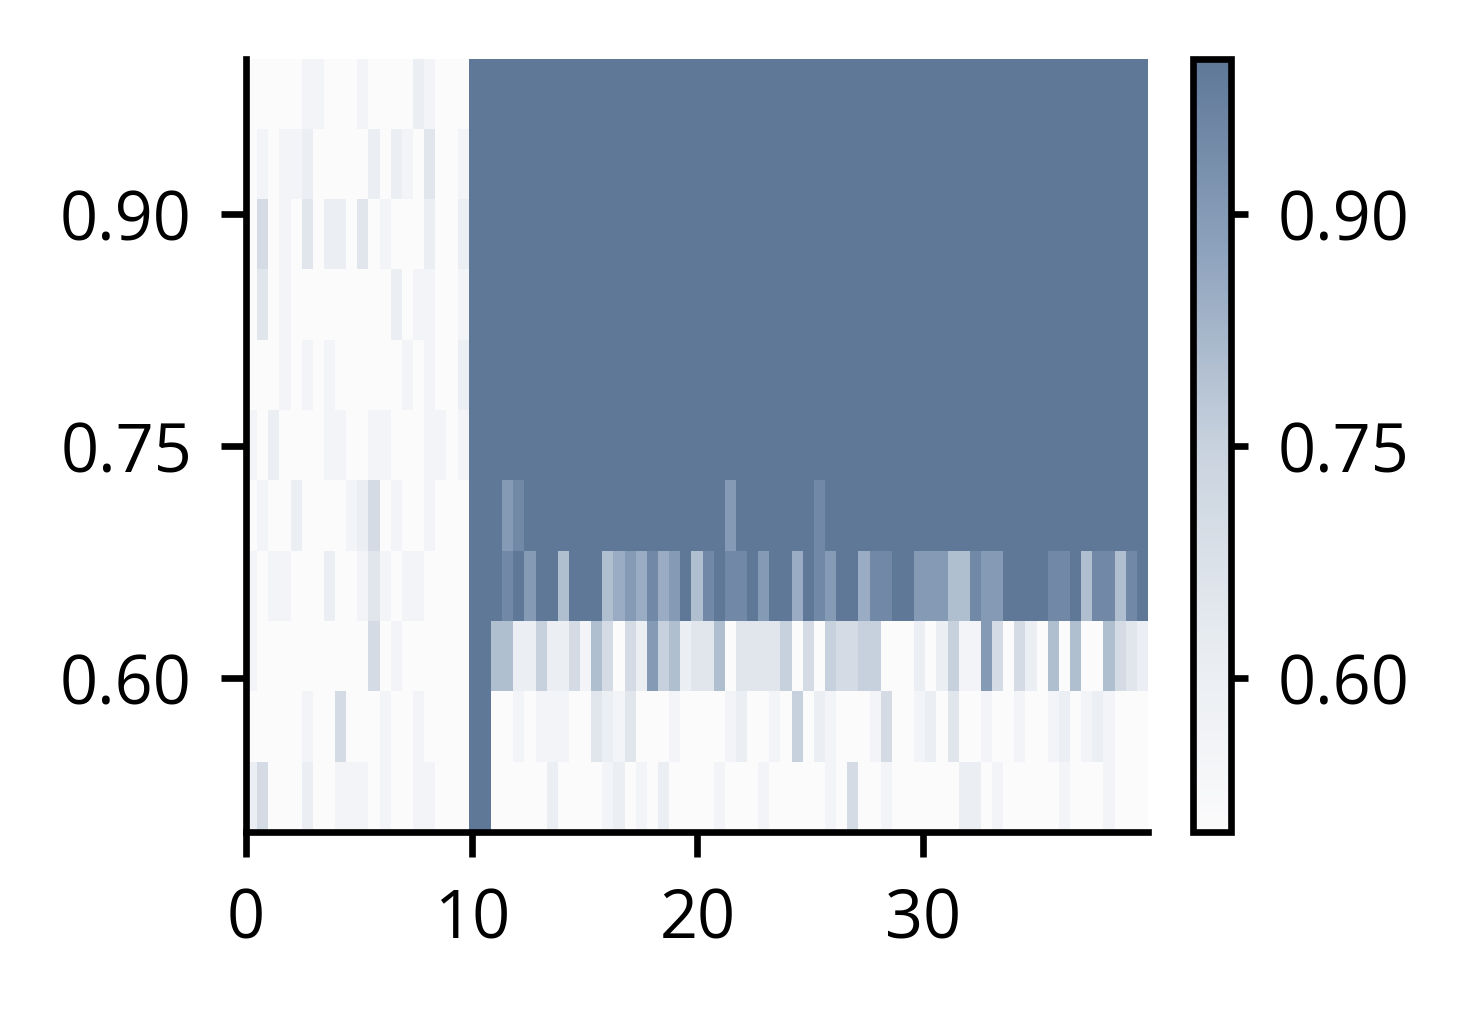

In [9]:
# Firing Rate Decoding accurarcy over time (mean across trials)
# Reuses fig_params, acc_cmap, CM, W, H from the cell above, so run that first.
selectivities = sorted(selectivities)
print(selectivities)
t = all_t_fr[selectivities[0]]
acc_matrix = np.vstack([all_acc_fr[s] for s in selectivities]) # shape (n_sel, n_time)

with mpl.rc_context(fig_params):
    fig, ax = plt.subplots(figsize=(W, H), constrained_layout=True)
    im = ax.imshow(
        acc_matrix, aspect='auto', origin='lower',
        extent=[t[0], t[-1], selectivities[0], selectivities[-1]],
        vmin=0.5, vmax=1.0,
        cmap=acc_cmap
    )
    ax.minorticks_off()
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    # ax.set_xlabel('Time (s)')
    # ax.set_ylabel('Feedback Selectivity')
    # ax.set_title('Firing Rate Decoding Over Time')

    cbar = fig.colorbar(im, ax=ax)
    # cbar.set_label('Decoding accuracy')
    cbar.locator = MaxNLocator(4)
    cbar.update_ticks()
    cbar.ax.minorticks_off()
    cbar.ax.tick_params(which='both', direction='out', length=2, width=0.8)
    cbar.outline.set_linewidth(0.8)

    # no bbox_inches='tight', so the file keeps the exact 4.6 x 4.6 cm size
    fig.savefig('saved_plots/Figure_6D/FR_Decoding_Over_Time.pdf')
    plt.show()